# 05 · Weather and delay risk

**Questions:** What do weather conditions look like at each port? Do adverse conditions coincide with changes in port
operations? Are pre-departure weather conditions at the origin/destination associated with delay class?

Caution on confounding: ports have very different climates (Hamburg ≈ 2 °C, Singapore ≈ 27 °C) and different baseline
delay rates. A pooled correlation between temperature and delay would largely be a *port* effect. Weather is therefore
also analysed as **anomalies within port** (value minus that port's mean).

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats as ss

from cargomind_eda import io, stats, features, plotting as P
from cargomind_eda.config import CLASSES, CLASS_COLORS

P.setup()
T = io.load_all()
wx, tel, dis = T["weather_hourly"], T["port_hourly_telemetry"], T["disruption_events"]
WX = ["temperature_2m_c", "relative_humidity_2m_pct", "precipitation_mm", "wind_speed_10m_kmh", "wind_gusts_10m_kmh",
      "wind_direction_10m_deg", "surface_pressure_hpa", "visibility_m"]

## E1. Weather climatology by port

In [2]:
clim = wx.groupby("port_id")[WX].agg(["median"]).droplevel(1, axis=1)
clim["p99_gust"] = wx.groupby("port_id").wind_gusts_10m_kmh.quantile(0.99)
clim["pct_hours_rain"] = wx.groupby("port_id").weather_code.apply(lambda x: (x >= 61).mean() * 100)
clim["pct_hours_thunderstorm"] = wx.groupby("port_id").weather_code.apply(lambda x: (x == 95).mean() * 100)
clim.round(1)

,temperature_2m_c,relative_humidity_2m_pct,precipitation_mm,wind_speed_10m_kmh,wind_gusts_10m_kmh,wind_direction_10m_deg,surface_pressure_hpa,visibility_m,p99_gust,pct_hours_rain,pct_hours_thunderstorm
port_id,,,,,,,,,,,
AEJEA,20,68,0,13.3,19.4,118,"1,013",2.38e+04,89.4,14.9,5.7
CNSHA,5.1,69,0,22.1,32.4,163,"1,013",2.388e+04,83.2,11.5,1.9
DEHAM,1.8,69,0,14.7,21.6,105,"1,013",2.374e+04,63.5,9.5,1.4
INMAA,25.9,69,0,14.9,21.8,152,"1,013",2.384e+04,70.4,8.4,1
INNSA,25,69,0,16.7,24.6,147,"1,013",2.39e+04,78.2,10.2,2.4
LKCMB,27,69,0,19,28.1,305,"1,013",2.378e+04,79.3,7.9,1.6
MYPKG,26.9,69,0,15.2,22,88.5,"1,013",2.386e+04,65.8,13.8,1.7
NLRTM,4,69,0,10.9,16.1,179,"1,013",2.385e+04,84.4,11.7,5.1
SGSIN,27.1,68,0,19.4,28.7,74,"1,013",2.384e+04,74.6,9.8,1


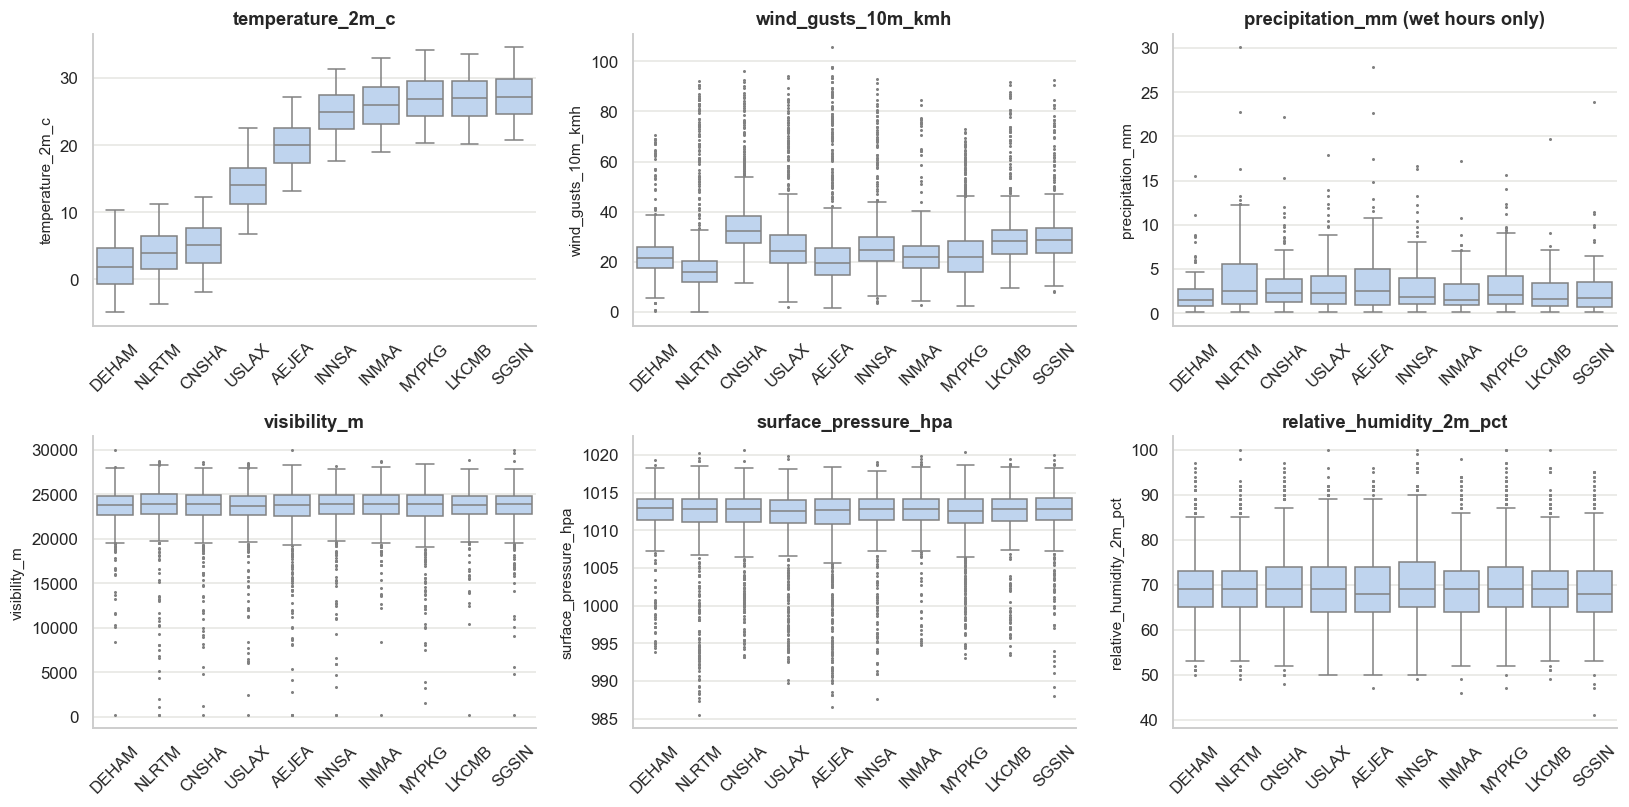

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7.5))
order = clim.sort_values("temperature_2m_c").index
for ax, c in zip(axes.flat, ["temperature_2m_c", "wind_gusts_10m_kmh", "precipitation_mm", "visibility_m", "surface_pressure_hpa", "relative_humidity_2m_pct"]):
    data = wx if c != "precipitation_mm" else wx[wx.precipitation_mm > 0]
    sns.boxplot(data=data, x="port_id", y=c, order=order, ax=ax, color="#b7d3f6", fliersize=1, linewidth=1)
    ax.set_title(c + (" (wet hours only)" if c == "precipitation_mm" else ""))
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=45)
P.save(fig, "05_weather_by_port")

### Weather code ↔ condition consistency, and the imputed-visibility ports

In [4]:
print(pd.crosstab(wx.weather_code, wx.weather_condition))
print("\nMedian precipitation by weather code:", wx.groupby("weather_code").precipitation_mm.median().to_dict())
vis_imputed = ["USLAX", "CNSHA", "LKCMB"]  # visibility entirely absent in raw (notebook 01)
v = wx.assign(group=np.where(wx.port_id.isin(vis_imputed), "visibility filled in cleaning", "visibility observed"))
print("\nSpearman(visibility, precipitation) by group:")
print(v.groupby("group").apply(lambda g: round(ss.spearmanr(g.visibility_m, g.precipitation_mm)[0], 3)).to_string())

weather_condition  clear  heavy rain  light rain  mainly clear  overcast  partly cloudy  rain  thunderstorm
weather_code                                                                                               
0                   2955           0           0             0         0              0     0             0
1                      0           0           0          2924         0              0     0             0
2                      0           0           0             0         0           2997     0             0
3                      0           0           0             0        25              0     0             0
61                     0           0         465             0         0              0     0             0
63                     0           0           0             0         0              0   287             0
65                     0          91           0             0         0              0     0             0
95                     0    

/var/folders/75/zcl7vfx51p99nhkfmp7v8vj80000gn/T/ipykernel_37349/455639557.py:6: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  print(v.groupby("group").apply(lambda g: round(ss.spearmanr(g.visibility_m, g.precipitation_mm)[0], 3)).to_string())


Weather codes map one-to-one onto conditions (WMO-style codes: 0–3 clear→overcast, 61/63/65 rain, 95 thunderstorm).
Overcast (code 3) is almost absent (25 hours), which is unusual but not invalid.

## E2. Do adverse weather conditions coincide with changes in port operations?

gust_band,<20,20–30,30–40,40–50,50–60,≥60
port-hours,3228,4150,1813,285,155,369


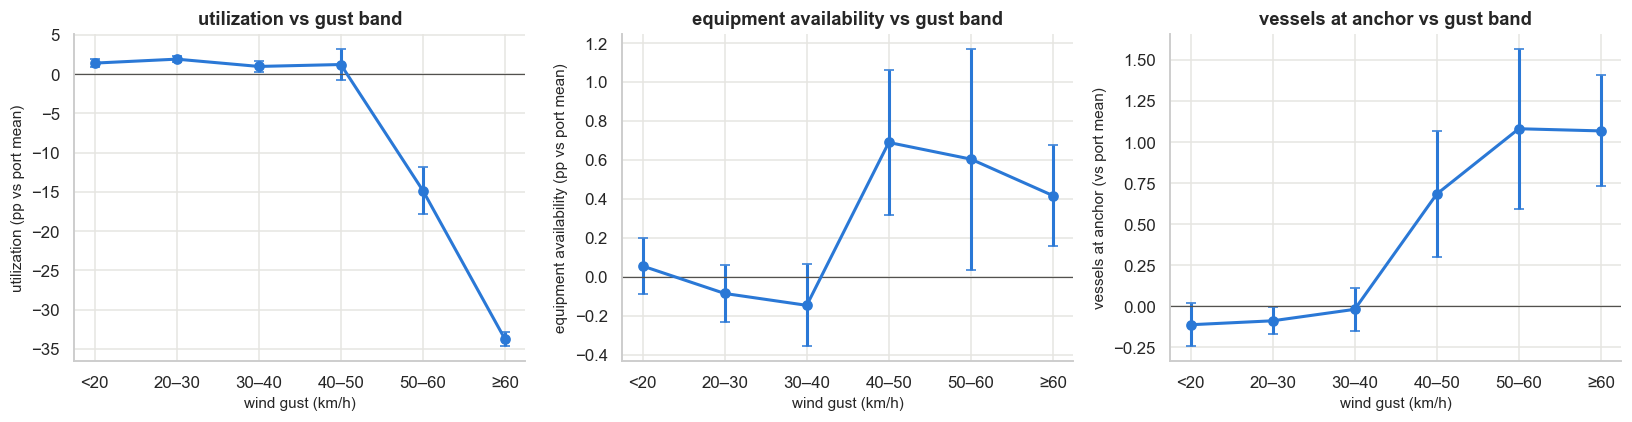

In [5]:
pw = tel.merge(wx, on=["port_id", "ts_hour"], validate="1:1")
for c in ["wind_gusts_10m_kmh", "precipitation_mm", "visibility_m"]:
    pw[c + "_anom"] = pw[c] - pw.groupby("port_id")[c].transform("mean")
for c in ["port_utilization_pct", "vessels_at_anchor", "equipment_availability_pct", "container_dwell_hours"]:
    pw[c + "_anom"] = pw[c] - pw.groupby("port_id")[c].transform("mean")
pw["gust_band"] = pd.cut(pw.wind_gusts_10m_kmh, [-1, 20, 30, 40, 50, 60, 200], labels=["<20", "20–30", "30–40", "40–50", "50–60", "≥60"])

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, c, lab in zip(axes, ["port_utilization_pct_anom", "equipment_availability_pct_anom", "vessels_at_anchor_anom"],
                      ["utilization (pp vs port mean)", "equipment availability (pp vs port mean)", "vessels at anchor (vs port mean)"]):
    g = pw.groupby("gust_band", observed=True)[c].agg(["mean", "sem", "size"])
    ax.errorbar(range(len(g)), g["mean"], yerr=1.96 * g["sem"], fmt="o-", color="#2a78d6", capsize=3)
    ax.set_xticks(range(len(g)), g.index)
    ax.axhline(0, color="#52514e", lw=0.8)
    ax.set_xlabel("wind gust (km/h)")
    ax.set_ylabel(lab)
    ax.set_title(f"{lab.split(' (')[0]} vs gust band")
P.save(fig, "05_gusts_vs_port_operations")
pw.groupby("gust_band", observed=True).size().rename("port-hours").to_frame().T

In [6]:
rows = []
for c in ["wind_gusts_10m_kmh", "wind_speed_10m_kmh", "precipitation_mm", "visibility_m", "surface_pressure_hpa", "temperature_2m_c", "relative_humidity_2m_pct"]:
    a = pw[c] - pw.groupby("port_id")[c].transform("mean")
    rows.append({"weather (within-port anomaly)": c, **{m: ss.spearmanr(a, pw[m + "_anom"])[0] for m in ["port_utilization_pct", "equipment_availability_pct", "vessels_at_anchor", "container_dwell_hours"]}})
pd.DataFrame(rows).set_index("weather (within-port anomaly)").round(3)

,port_utilization_pct,equipment_availability_pct,vessels_at_anchor,container_dwell_hours
weather (within-port anomaly),,,,
wind_gusts_10m_kmh,-0.126,0.007,0.102,0.101
wind_speed_10m_kmh,-0.122,0.007,0.102,0.102
precipitation_mm,-0.076,-0.011,0.062,0.074
visibility_m,0.05,0.004,-0.03,-0.023
surface_pressure_hpa,0.131,-0.007,-0.087,-0.083
temperature_2m_c,0.225,-0.008,0.008,0.008
relative_humidity_2m_pct,-0.071,0.009,0.024,0.02


### Weather during logged "weather" disruption events

In [7]:
inside = pd.Series(False, index=pw.index)
for _, e in dis[dis.event_type == "weather"].iterrows():
    inside |= (pw.port_id == e.port_id) & (pw.ts_hour >= e.event_start) & (pw.ts_hour < e.event_end)
cmp = pw.groupby(inside)[["wind_gusts_10m_kmh", "wind_speed_10m_kmh", "precipitation_mm", "visibility_m"]].median().T
cmp.columns = ["outside weather events", "inside weather events"]
print("hours inside weather events:", inside.sum())
cmp

hours inside weather events: 423


,outside weather events,inside weather events
wind_gusts_10m_kmh,23.5,71
wind_speed_10m_kmh,16,47.3
precipitation_mm,0,0.7
visibility_m,2.386e+04,2.223e+04


Logged weather disruptions ("high winds suspended crane operations") line up with much higher gusts, confirming the event
log and the hourly weather are mutually consistent. Gusts above ~50 km/h coincide with lower utilization and equipment
availability and a growing anchor queue.

## E3. Pre-departure weather vs delay class

In [8]:
f = features.build_shipment_features(lag_hours=1, tables=T)
sea = f[f.shipping_mode == "sea"].copy()
wx_feats = [c for c in sea.columns if c.startswith(("wx_o_", "wx_d_", "wx_h_"))]
wt = stats.screen_numeric(sea, wx_feats)
wt["magnitude_Crit_vs_OnTime"] = wt["cliff_Critical_vs_On-Time"].map(stats.magnitude_label)
wt = wt.reindex(wt["cliff_Critical_vs_On-Time"].abs().sort_values(ascending=False).index)
P.save_table(wt, "05_weather_features_vs_class")
wt[["n", "tie_share", "epsilon_sq", "median_On-Time", "median_At-Risk", "median_Critical", "cliff_Critical_vs_On-Time", "cliff_At-Risk_vs_On-Time", "spearman_rho_delay_h", "magnitude_Crit_vs_OnTime"]].round(3).head(25)

,n,tie_share,epsilon_sq,median_On-Time,median_At-Risk,median_Critical,cliff_Critical_vs_On-Time,cliff_At-Risk_vs_On-Time,spearman_rho_delay_h,magnitude_Crit_vs_OnTime
feature,,,,,,,,,,
wx_o_precip_sum24,9347,0.16,0.073,2.2,2.9,7.7,0.44,0.136,0.253,medium
wx_o_gust_max24,9347,0.016,0.074,34.2,36.1,48.7,0.439,0.136,0.259,medium
wx_o_visibility_min24,9347,0.03,0.062,2.045e+04,2.012e+04,1.666e+04,-0.407,-0.118,-0.229,medium
wx_o_wind_mean24,9347,0.001,0.053,16.94,17.97,21.99,0.374,0.112,0.217,medium
wx_o_thunderstorm_hours24,9347,0.926,0.178,0,0,0,0.314,0.047,0.344,small
wx_o_surface_pressure_hpa,9347,0.021,0.035,"1,013","1,013","1,012",-0.303,-0.038,-0.153,small
wx_o_wind_gusts_10m_kmh,9347,0.006,0.026,25.2,25.6,30.7,0.265,0.044,0.135,small
wx_o_wind_speed_10m_kmh,9347,0.009,0.024,17.1,17.2,20.1,0.253,0.035,0.126,small
wx_o_weather_code,9347,0.299,0.016,1,1,2,0.197,0.018,0.093,small


### Controlling for port: within-origin anomalies
If the weather signal were just "NLRTM is windy and NLRTM is late", it would vanish within port.

In [9]:
for c in ["wx_o_gust_max24", "wx_o_precip_sum24", "wx_o_thunderstorm_hours24", "wx_o_visibility_min24", "wx_o_temperature_2m_c", "wx_o_surface_pressure_hpa"]:
    sea[c + "_anom"] = sea[c] - sea.groupby("origin_port_id")[c].transform("mean")
anom = stats.screen_numeric(sea, [c for c in sea.columns if c.endswith("_anom") and c.startswith("wx_o_")])
anom[["epsilon_sq", "cliff_Critical_vs_On-Time", "spearman_rho_delay_h"]].round(3).sort_values("spearman_rho_delay_h", key=abs, ascending=False)

,epsilon_sq,cliff_Critical_vs_On-Time,spearman_rho_delay_h
feature,,,
wx_o_precip_sum24_anom,0.072,0.431,0.267
wx_o_gust_max24_anom,0.077,0.454,0.258
wx_o_visibility_min24_anom,0.063,-0.408,-0.242
wx_o_surface_pressure_hpa_anom,0.032,-0.291,-0.152
wx_o_thunderstorm_hours24_anom,0.018,0.221,0.116
wx_o_temperature_2m_c_anom,0.001,-0.027,-0.002


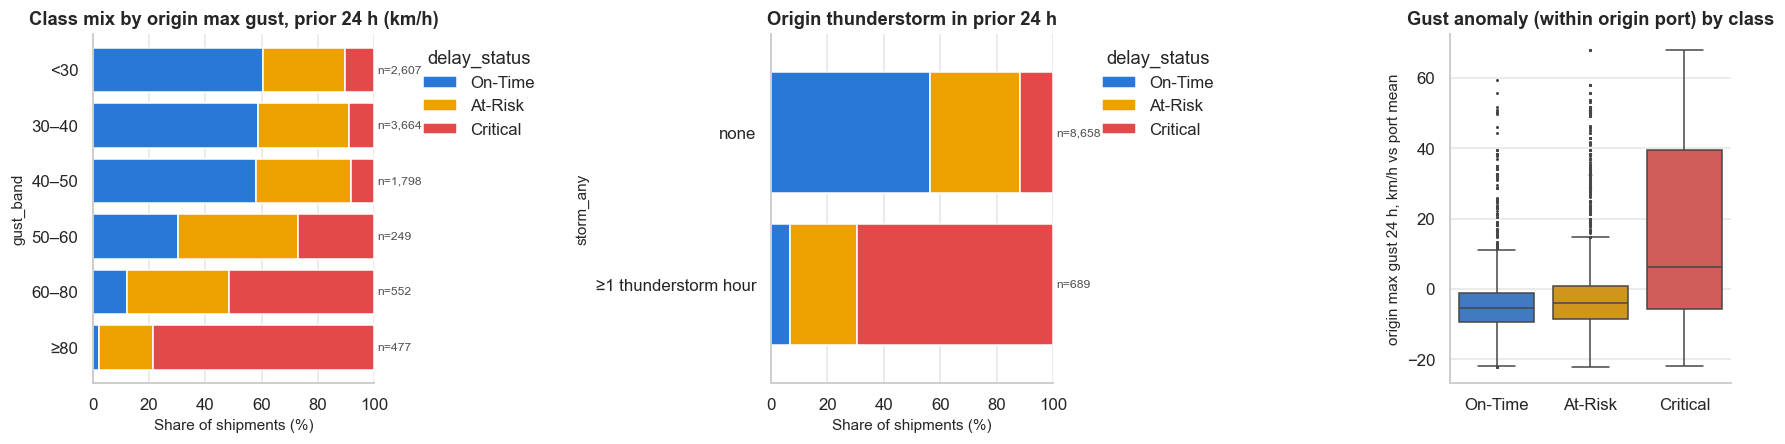

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
sea["gust_band"] = pd.cut(sea.wx_o_gust_max24, [0, 30, 40, 50, 60, 80, 200], labels=["<30", "30–40", "40–50", "50–60", "60–80", "≥80"])
P.stacked_class_bar(sea, "gust_band", ax=axes[0], order=["<30", "30–40", "40–50", "50–60", "60–80", "≥80"], title="Class mix by origin max gust, prior 24 h (km/h)")
sea["storm_any"] = np.where(sea.wx_o_thunderstorm_hours24 > 0, "≥1 thunderstorm hour", "none")
P.stacked_class_bar(sea, "storm_any", ax=axes[1], order=["none", "≥1 thunderstorm hour"], title="Origin thunderstorm in prior 24 h")
sns.boxplot(data=sea, x="delay_status", y="wx_o_gust_max24_anom", hue="delay_status", legend=False, order=CLASSES, palette=CLASS_COLORS, ax=axes[2], fliersize=1, linewidth=1)
axes[2].set_ylabel("origin max gust 24 h, km/h vs port mean")
axes[2].set_xlabel("")
axes[2].set_title("Gust anomaly (within origin port) by class")
P.save(fig, "05_weather_by_class")

### Wind direction
Direction is circular (0° = 360°), so it is analysed as 45° sectors (categorical), not as a linear number.

In [11]:
wd = T["weather_hourly"][["port_id", "ts_hour", "wind_direction_10m_deg"]].rename(columns={"port_id": "origin_port_id", "ts_hour": "cutoff_ts"})
sea = sea.merge(wd, on=["origin_port_id", "cutoff_ts"], how="left", validate="m:1")
sea["sector"] = pd.cut(sea.wind_direction_10m_deg % 360, np.arange(0, 361, 45), right=False, labels=["N–NE", "NE–E", "E–SE", "SE–S", "S–SW", "SW–W", "W–NW", "NW–N"])
print(stats.chi2_vs_target(sea, "sector"))
r = []
for p, g in sea.groupby("origin_port_id"):
    t = stats.chi2_vs_target(g, "sector")
    r.append({"origin": p, "n": len(g), "cramers_v": t["cramers_v"], "p": t["p_value"]})
pd.DataFrame(r).set_index("origin").round(3)

{'feature': 'sector', 'levels': 8, 'chi2': np.float64(226.23913730098985), 'dof': 14, 'p_value': np.float64(2.2915836968590836e-40), 'cramers_v': np.float64(0.10656302922268324), 'min_expected': np.float64(86.7522199636247), 'pct_cells_expected_lt5': np.float64(0.0)}


,n,cramers_v,p
origin,,,
AEJEA,892,0.206,0
CNSHA,2080,0.255,0
DEHAM,670,0.058,0.182
INMAA,409,0.129,0.012
INNSA,579,0.089,0.029
LKCMB,630,0.135,0
MYPKG,851,0.282,0
NLRTM,821,0.164,0
SGSIN,1673,0.093,0


In [12]:
# Is direction informative beyond storminess? Repeat within calm-to-moderate conditions only.
calm = sea[sea.wx_o_gust_max24 < 40]
print(f"calm subset (prior-24h max gust < 40 km/h): n = {len(calm)}")
r = []
for p, g in calm.groupby("origin_port_id"):
    t = stats.chi2_vs_target(g, "sector")
    r.append({"origin": p, "n": len(g), "cramers_v": t["cramers_v"], "p": t["p_value"]})
pd.DataFrame(r).set_index("origin").round(3)

calm subset (prior-24h max gust < 40 km/h): n = 6270


,n,cramers_v,p
origin,,,
AEJEA,685,0,0.498
CNSHA,785,0.239,0
DEHAM,629,0.091,0.041
INMAA,376,0.052,0.298
INNSA,456,0.088,0.042
LKCMB,414,0.112,0.026
MYPKG,707,0.296,0
NLRTM,684,0.159,0
SGSIN,980,0.152,0


## E4. Findings — weather

* Ranking note: several weather features are mostly zero (e.g. 24 h thunderstorm hours). Heavy ties inflate the
  Kruskal–Wallis ε², so features are ranked by Cliff's δ (Critical vs On-Time) and Spearman ρ instead (`tie_share` column).
* **Wind gusts at the origin in the 24 h before departure** are the most informative weather variable. Median prior-24 h max
  gust: 34 km/h (On-Time), 36 km/h (At-Risk), 49 km/h (Critical); Cliff's δ Critical vs On-Time = 0.44 (medium). The signal
  **survives within-port centring** (δ = 0.45, ρ = 0.26), so it is not just a port effect. Critical share rises sharply once
  gusts exceed ~50 km/h.
* **24 h precipitation** at origin behaves almost identically (δ = 0.44; within-port δ = 0.43). Thunderstorm hours carry a
  large *pooled* association (ρ = 0.34) that shrinks within port (ρ = 0.12), so part of it reflects storm-prone ports.
* Weather mostly separates **Critical** from the rest. At-Risk vs On-Time differences are small (δ ≈ 0.11–0.14).
* **Visibility** (24 h minimum) is associated with risk (δ = −0.41). For USLAX, CNSHA and LKCMB the processed visibility
  values were filled during cleaning (raw had none). The filled values keep a realistic relationship with precipitation
  (ρ = −0.37, the same as observed ports), so they look model-based, but they are not measurements.
* **Temperature, humidity and pressure levels** mostly encode *which port* (climate). Temperature has no association once
  centred within port (δ = −0.03). The pressure anomaly keeps a small association (δ = −0.29): low pressure accompanies storms.
* **Wind direction** shows a within-port association at most ports (V up to 0.28), and at CNSHA, MYPKG, NLRTM and SGSIN it
  persists in calm conditions (prior-24 h max gust < 40 km/h). It disappears at AEJEA. Wind direction is strongly persistent
  in time, so within a ~6-week window a sector effectively tags *a period*, and periods differ in disruptions and backlog.
  The most plausible reading is that direction proxies for time/synoptic regime, not a physical driver. It is a candidate for
  overfitting; treat it as low priority, encode it circularly (sin/cos) if used, and test it under a time-based split.
* **Destination and hub weather at departure time** are weak (|δ| ≤ 0.17). The relevant destination weather is the weather at
  *arrival*, which is unknown at prediction time without forecasts (notebook 09).
* Mechanism (consistent with, but not proof of, causation): logged "high winds" disruption hours have a median gust of 71 km/h
  vs 24 km/h otherwise. Within port, higher gusts coincide with lower utilization (ρ = −0.13) and longer anchor queues
  (ρ = +0.10), while equipment availability is unrelated to weather (ρ ≈ 0). Weather probably acts *through* port throughput,
  so weather and port-congestion features will be correlated (notebook 08).